In [1]:
import pandas as pd
import numpy as np

train = pd.read_csv("../data/train.csv")
features = pd.read_csv("../data/features.csv")
stores = pd.read_csv("../data/stores.csv")

In [2]:
#Convert dates
train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])

In [3]:
#Merge datasets
data = train.merge(features, on=["Store", "Date"], how="left")
data = data.merge(stores, on="Store", how="left")

data = data.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)

In [4]:
data.head()


,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


In [5]:
data.shape

(421570, 17)

In [6]:
data.isna().sum().sort_values(ascending=False).head(10)

MarkDown2      310322
MarkDown4      286603
MarkDown3      284479
MarkDown1      270889
MarkDown5      270138
Store               0
IsHoliday_x         0
Dept                0
Date                0
Temperature         0
dtype: int64

In [7]:
#Handle missing values
markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

for col in markdown_cols:
    data[col] = data[col].fillna(0)

In [8]:
# handled the missing values
data[markdown_cols].isna().sum()

MarkDown1    0
MarkDown2    0
MarkDown3    0
MarkDown4    0
MarkDown5    0
dtype: int64

In [9]:
#Create calendar features
data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Week"] = data["Date"].dt.isocalendar().week.astype(int)
data["Quarter"] = data["Date"].dt.quarter

In [10]:
data[["Date", "Year", "Month", "Week", "Quarter"]].head()

,Date,Year,Month,Week,Quarter
0,2010-02-05,2010,2,5,1
1,2010-02-12,2010,2,6,1
2,2010-02-19,2010,2,7,1
3,2010-02-26,2010,2,8,1
4,2010-03-05,2010,3,9,1


In [11]:
#group by
group_cols = ["Store", "Dept"]

In [12]:
#create lags
data["lag_1"] = data.groupby(group_cols)["Weekly_Sales"].shift(1)
data["lag_2"] = data.groupby(group_cols)["Weekly_Sales"].shift(2)
data["lag_4"] = data.groupby(group_cols)["Weekly_Sales"].shift(4)
data["lag_12"] = data.groupby(group_cols)["Weekly_Sales"].shift(12)
data["lag_52"] = data.groupby(group_cols)["Weekly_Sales"].shift(52)

In [13]:
#checking if the lags work correctly
sample = data[(data["Store"] == 1) & (data["Dept"] == 1)].copy()
sample[["Date", "Weekly_Sales", "lag_1", "lag_2", "lag_4"]].head(10)

,Date,Weekly_Sales,lag_1,lag_2,lag_4
0,2010-02-05,24924.50,NaN,NaN,NaN
1,2010-02-12,46039.49,24924.50,NaN,NaN
2,2010-02-19,41595.55,46039.49,24924.50,NaN
3,2010-02-26,19403.54,41595.55,46039.49,NaN
4,2010-03-05,21827.90,19403.54,41595.55,24924.50
5,2010-03-12,21043.39,21827.90,19403.54,46039.49
6,2010-03-19,22136.64,21043.39,21827.90,41595.55
7,2010-03-26,26229.21,22136.64,21043.39,19403.54
8,2010-04-02,57258.43,26229.21,22136.64,21827.90
9,2010-04-09,42960.91,57258.43,26229.21,21043.39


In [14]:
#Rolling features
data["rolling_mean_4"] = data.groupby(group_cols)["Weekly_Sales"].transform(lambda x: x.shift(1).rolling(4).mean())

data["rolling_mean_12"] = data.groupby(group_cols)["Weekly_Sales"].transform(lambda x: x.shift(1).rolling(12).mean())

data["rolling_std_4"] = data.groupby(group_cols)["Weekly_Sales"].transform(lambda x: x.shift(1).rolling(4).std())

In [15]:
sample = data[(data["Store"] == 1) & (data["Dept"] == 1)].copy()

sample[["Date", "Weekly_Sales", "rolling_mean_4"]].head(10)

,Date,Weekly_Sales,rolling_mean_4
0,2010-02-05,24924.50,NaN
1,2010-02-12,46039.49,NaN
2,2010-02-19,41595.55,NaN
3,2010-02-26,19403.54,NaN
4,2010-03-05,21827.90,32990.7700
5,2010-03-12,21043.39,32216.6200
6,2010-03-19,22136.64,25967.5950
7,2010-03-26,26229.21,21102.8675
8,2010-04-02,57258.43,22809.2850
9,2010-04-09,42960.91,31666.9175


In [16]:
#Drop rows with missing lag/rolling values
ml_data = data.dropna(subset=[
    "lag_1", "lag_2", "lag_4", "lag_12", "lag_52",
    "rolling_mean_4", "rolling_mean_12", "rolling_std_4"
]).copy()

In [17]:
ml_data.shape

(261083, 29)

In [18]:
#Train/Test split
split_date = pd.Timestamp("2012-04-10")

train_ml = ml_data[ml_data["Date"] <= split_date].copy()
test_ml  = ml_data[ml_data["Date"] > split_date].copy()

print(train_ml.shape, test_ml.shape)

# it becomes roughly 68/32, not 80/20, if we use the same date as time-series models, should I keep it or pick a different date to achieve exactly 80/20?

(176885, 29) (84198, 29)


In [19]:
print(train_ml["Date"].max())
print(test_ml["Date"].min())
# ensuring that train ends before test begins

2012-04-06 00:00:00
2012-04-13 00:00:00


In [20]:
# defineing features and target
target = "Weekly_Sales"

feature_cols = [
    "Store", "Dept", "Type", "Size",
    "IsHoliday_x",
    "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5",
    "Year", "Month", "Week", "Quarter",
    "lag_1", "lag_2", "lag_4", "lag_12", "lag_52",
    "rolling_mean_4", "rolling_mean_12", "rolling_std_4"
]

X_train = train_ml[feature_cols]
y_train = train_ml[target]

X_test = test_ml[feature_cols]
y_test = test_ml[target]

In [21]:
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

X_train.head()
# final check before first ML model

(176885, 26) (84198, 26)
(176885,) (84198,)


,Store,Dept,Type,Size,IsHoliday_x,Temperature,Fuel_Price,CPI,Unemployment,MarkDown1,...,Week,Quarter,lag_1,lag_2,lag_4,lag_12,lag_52,rolling_mean_4,rolling_mean_12,rolling_std_4
52,1,1,A,151315,False,42.27,2.989,212.566881,7.742,0.0,...,5,1,18461.18,17341.47,15984.24,19549.39,24924.50,17286.6475,25087.749167,1013.925386
53,1,1,A,151315,True,36.39,3.022,212.936705,7.742,0.0,...,6,1,21665.76,18461.18,17359.70,19552.84,46039.49,18707.0275,25264.113333,2040.798674
54,1,1,A,151315,False,57.36,3.045,213.247885,7.742,0.0,...,7,1,37887.17,21665.76,17341.47,18820.29,41595.55,23838.8950,26791.974167,9543.110891
55,1,1,A,151315,False,62.90,3.065,213.535609,7.742,0.0,...,8,1,46845.87,37887.17,18461.18,22517.56,19403.54,31214.9950,29127.439167,13449.781394
56,1,1,A,151315,False,59.58,3.288,213.823333,7.742,0.0,...,9,1,19363.83,46845.87,21665.76,31497.65,21827.90,31440.6575,28864.628333,13169.111324


# Linear Regression

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [23]:
#Define feature groups
categorical_features = ["Store", "Dept", "Type", "IsHoliday_x"]

numeric_features = [
    "Size", "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5",
    "Year", "Month", "Week", "Quarter",
    "lag_1", "lag_2", "lag_4", "lag_12", "lag_52",
    "rolling_mean_4", "rolling_mean_12", "rolling_std_4"
]

In [24]:
# Define transformations
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [25]:
#Combine them
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [26]:
# Build Linear Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [27]:
# train the model
lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Store','Dept','Type',...,'rolling_mean_4','rolling_mean_12', 'rolling_std_4']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of

In [28]:
# Make predictions
lr_pred = lr_model.predict(X_test)

In [29]:
# define evaluation function and evaluate model
def evaluate_forecast(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mask = (y_true > 0) & (~np.isnan(y_pred))
    if mask.sum() == 0:
        mape = np.nan
    else:
        mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

    return mae, rmse, mape

In [30]:
lr_mae, lr_rmse, lr_mape = evaluate_forecast(y_test.values, lr_pred)

print("=== Linear Regression Results ===")
print(f"MAE:  {lr_mae:,.2f}")
print(f"RMSE: {lr_rmse:,.2f}")
print(f"MAPE: {lr_mape:.2f}%")

=== Linear Regression Results ===
MAE:  1,764.26
RMSE: 3,198.12
MAPE: 3442.64%


In [31]:
# MAPE is huge so only for it use positive values

Due to the presence of low-volume sales at the store–department level, MAPE computed at the individual observation level was unstable. Therefore, evaluation for machine learning models was also performed on aggregated weekly sales to ensure consistency with time-series models and to obtain meaningful percentage-based error metrics.

In [32]:
# Aggregate actual sales
weekly_actual = test_ml.groupby("Date")["Weekly_Sales"].sum()

# Aggregate predictions
test_pred_df = test_ml[["Date"]].copy()
test_pred_df["Predicted"] = lr_pred
weekly_pred = test_pred_df.groupby("Date")["Predicted"].sum()

In [33]:
lr_mae_agg, lr_rmse_agg, lr_mape_agg = evaluate_forecast(
    weekly_actual.values,
    weekly_pred.values
)

print("=== Linear Regression (Aggregated) ===")
print(f"MAE:  {lr_mae_agg:,.2f}")
print(f"RMSE: {lr_rmse_agg:,.2f}")
print(f"MAPE: {lr_mape_agg:.2f}%")

=== Linear Regression (Aggregated) ===
MAE:  2,263,125.19
RMSE: 2,576,644.02
MAPE: 4.91%


Linear Regression, despite leveraging engineered temporal and contextual features, underperformed compared to classical time-series models. This suggests that retail demand exhibits nonlinear relationships and complex interactions that cannot be adequately captured by a purely linear model.

Feature engineering alone is not enough — the model must also be capable of capturing nonlinear patterns.

Although evaluation is performed at the aggregated level for consistency with time-series models, machine learning models operate at a disaggregated (store–department) level. Feature engineering enables these models to capture temporal and contextual patterns at a granular level, which collectively improve overall demand forecasting performance when aggregated.

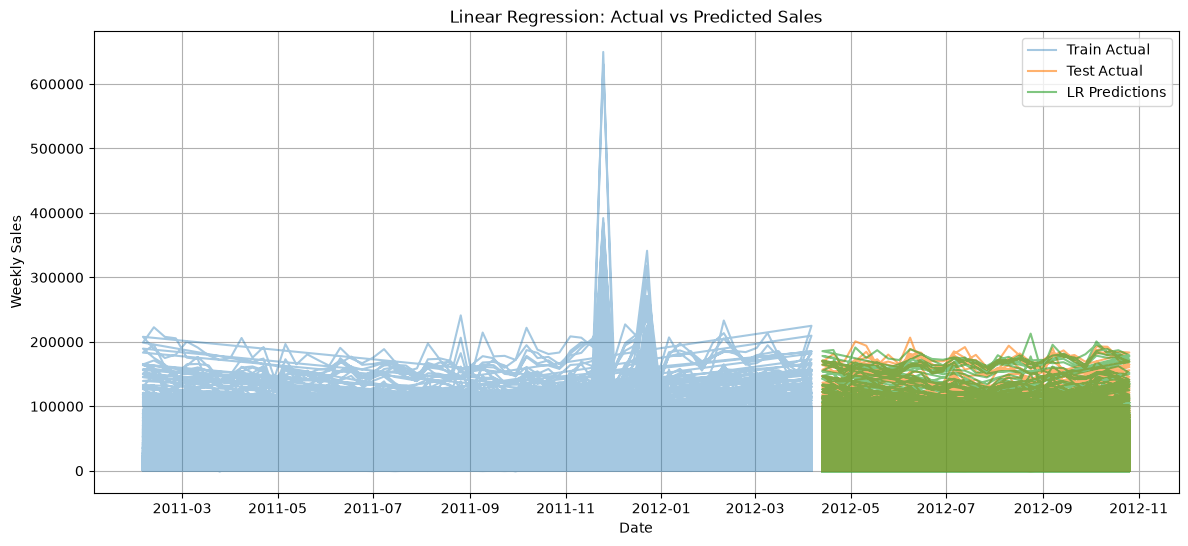

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(train_ml["Date"], y_train.values, label="Train Actual", alpha=0.4)
plt.plot(test_ml["Date"], y_test.values, label="Test Actual", alpha=0.6)
plt.plot(test_ml["Date"], lr_pred, label="LR Predictions", alpha=0.6)

plt.title("Linear Regression: Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

messy


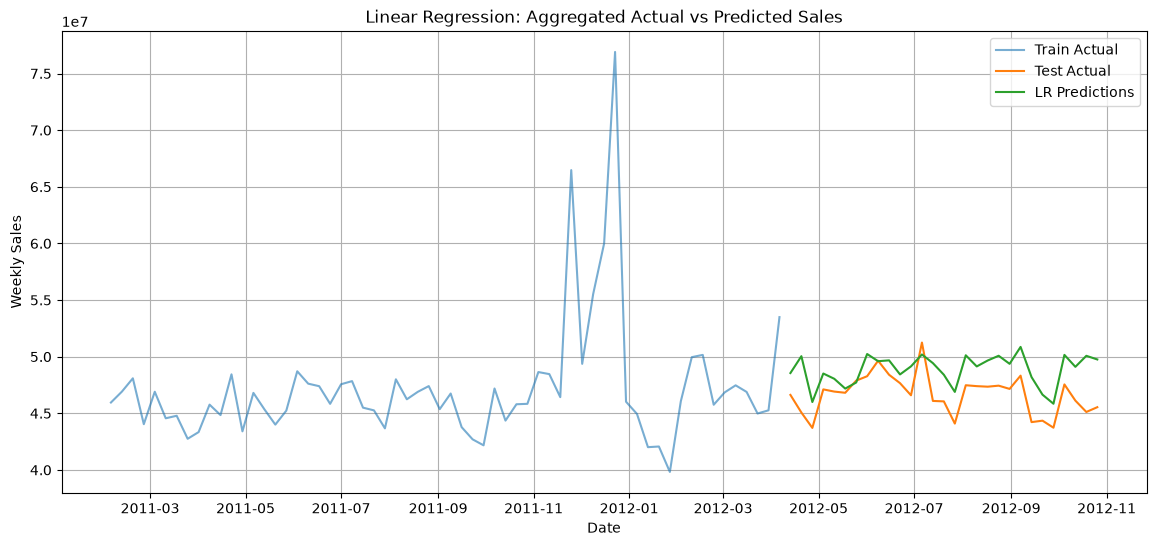

In [35]:
#plot the aggregated predictions
# Aggregate train actual
train_weekly = train_ml.groupby("Date")["Weekly_Sales"].sum()

# Aggregate test actual
test_weekly = test_ml.groupby("Date")["Weekly_Sales"].sum()

# Aggregate predictions
test_pred_df = test_ml[["Date"]].copy()
test_pred_df["Predicted"] = lr_pred
pred_weekly = test_pred_df.groupby("Date")["Predicted"].sum()

plt.figure(figsize=(14,6))

plt.plot(train_weekly.index, train_weekly.values, label="Train Actual", alpha=0.6)
plt.plot(test_weekly.index, test_weekly.values, label="Test Actual")
plt.plot(pred_weekly.index, pred_weekly.values, label="LR Predictions")

plt.title("Linear Regression: Aggregated Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

# Random Forest

In [36]:
from sklearn.ensemble import RandomForestRegressor

In [37]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

In [38]:
#rf_model.fit(X_train, y_train)
#it only can work with numerical values so colums of store types "A, B and C" should be converted in numerical (one hot encoding)

In [39]:
categorical_cols = ["Type"]

In [40]:
#apply encoding
X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

In [41]:
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [42]:
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

# Only for positive actual sales
mask = y_test > 0
rf_mape = np.mean(np.abs((y_test[mask] - rf_pred[mask]) / y_test[mask])) * 100

print("=== Random Forest Results ===")
print(f"MAE:  {rf_mae:,.2f}")
print(f"RMSE: {rf_rmse:,.2f}")
print(f"MAPE: {rf_mape:.2f}%")

=== Random Forest Results ===
MAE:  1,328.98
RMSE: 2,861.64
MAPE: 245.26%


In [44]:
rf_eval_df = test_ml[["Date", "Weekly_Sales"]].copy()
rf_eval_df["Predicted"] = rf_pred

rf_agg = rf_eval_df.groupby("Date").agg({
    "Weekly_Sales": "sum",
    "Predicted": "sum"
})

rf_agg_mae = mean_absolute_error(rf_agg["Weekly_Sales"], rf_agg["Predicted"])
rf_agg_rmse = np.sqrt(mean_squared_error(rf_agg["Weekly_Sales"], rf_agg["Predicted"]))

mask_agg = rf_agg["Weekly_Sales"] > 0
rf_agg_mape = np.mean(
    np.abs((rf_agg.loc[mask_agg, "Weekly_Sales"] - rf_agg.loc[mask_agg, "Predicted"]) / rf_agg.loc[mask_agg, "Weekly_Sales"])
) * 100

print("=== Random Forest (Aggregated) ===")
print(f"MAE:  {rf_agg_mae:,.2f}")
print(f"RMSE: {rf_agg_rmse:,.2f}")
print(f"MAPE: {rf_agg_mape:.2f}%")

=== Random Forest (Aggregated) ===
MAE:  1,028,603.69
RMSE: 1,352,804.49
MAPE: 2.22%


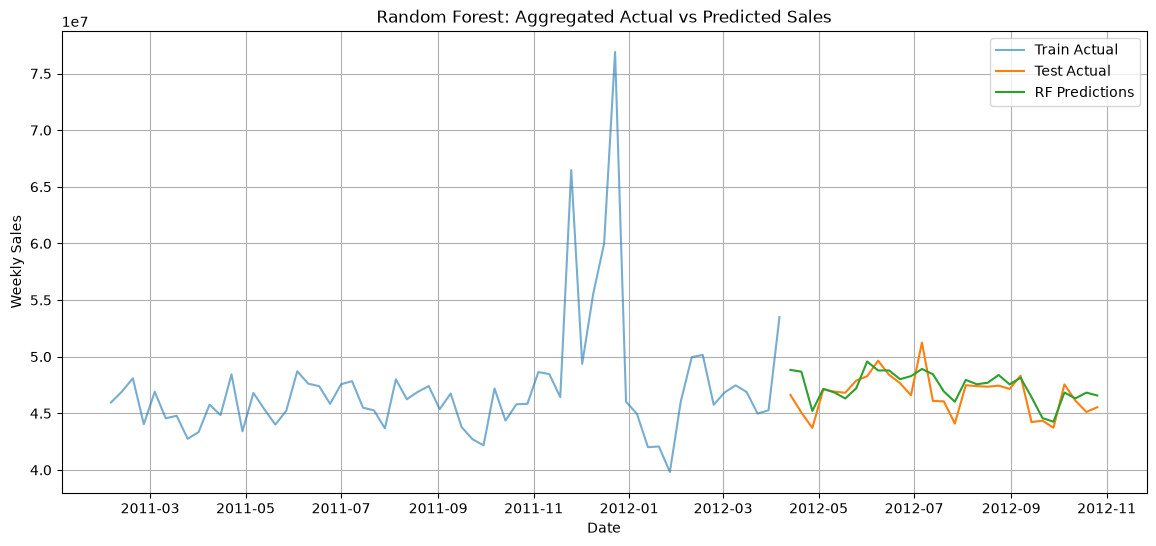

In [45]:
import matplotlib.pyplot as plt

train_weekly = train_ml.groupby("Date")["Weekly_Sales"].sum()
test_weekly = test_ml.groupby("Date")["Weekly_Sales"].sum()

rf_pred_df = test_ml[["Date"]].copy()
rf_pred_df["Predicted"] = rf_pred
rf_pred_weekly = rf_pred_df.groupby("Date")["Predicted"].sum()

plt.figure(figsize=(14,6))
plt.plot(train_weekly.index, train_weekly.values, label="Train Actual", alpha=0.6)
plt.plot(test_weekly.index, test_weekly.values, label="Test Actual")
plt.plot(rf_pred_weekly.index, rf_pred_weekly.values, label="RF Predictions")

plt.title("Random Forest: Aggregated Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
import pandas as pd

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

rf_importance.head(10)

,Feature,Importance
21,lag_52,0.822778
17,lag_1,0.135235
22,rolling_mean_4,0.029168
23,rolling_mean_12,0.003638
19,lag_4,0.002405
10,MarkDown3,0.001171
20,lag_12,0.001052
18,lag_2,0.000962
1,Dept,0.000649
24,rolling_std_4,0.000640


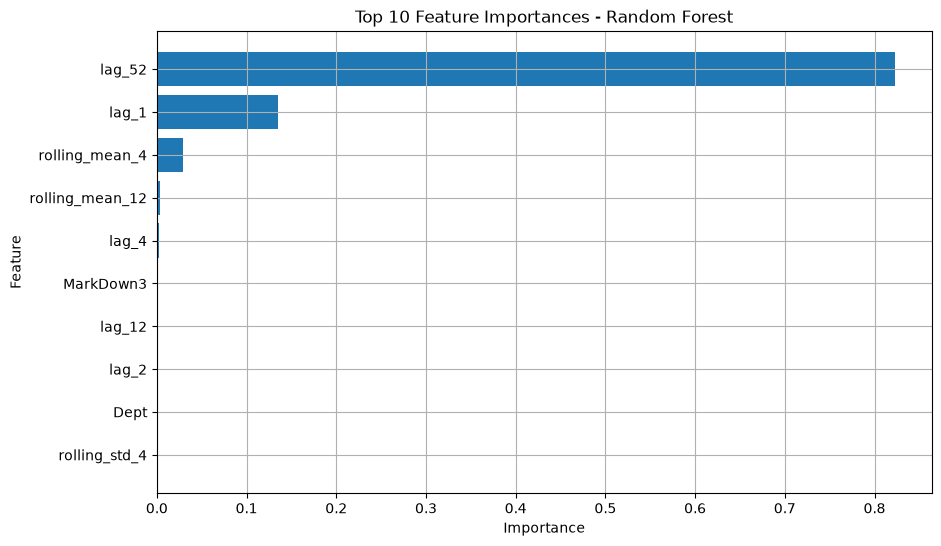

In [47]:
plt.figure(figsize=(10,6))
plt.barh(rf_importance["Feature"].head(10)[::-1], rf_importance["Importance"].head(10)[::-1])
plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(True)
plt.show()

The Random Forest model demonstrated strong predictive performance, achieving an aggregated MAPE of 2.22%, which is very close to the best-performing SARIMA model. This indicates that the model effectively captured the underlying demand patterns through feature engineering. By incorporating lagged sales, rolling statistics, and temporal indicators, the model was able to approximate trend and seasonality while also capturing nonlinear relationships and interactions between variables.

At the disaggregated level, the model exhibited higher error metrics due to the inherent variability and presence of low sales values, which disproportionately affect percentage-based measures such as MAPE. However, when evaluated at the aggregated level, the predictions aligned closely with actual demand, suggesting that the model is reliable for overall forecasting purposes.

Compared to Linear Regression, Random Forest performed significantly better, highlighting the importance of modeling nonlinear relationships in retail demand data. While the model does not explicitly incorporate time-series structure like SARIMA, its competitive performance demonstrates that well-engineered features can effectively substitute for explicit temporal modeling. Nevertheless, the model remains less interpretable and may require careful tuning and feature design to generalize well.

In [48]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["SARIMA", "Linear Regression", "Random Forest"],
    "MAE": [
        1034871,          # SARIMA (from your earlier results)
        2263157.58,       # LR aggregated
        1028660.89        # RF aggregated
    ],
    "RMSE": [
        1443201,          # SARIMA
        2576671.35,       # LR
        1352851.19        # RF
    ],
    "MAPE (%)": [
        2.19,             # SARIMA
        4.91,             # LR
        2.22              # RF
    ]
})

comparison

,Model,MAE,RMSE,MAPE (%)
0,SARIMA,1034871.00,1443201.00,2.19
1,Linear Regression,2263157.58,2576671.35,4.91
2,Random Forest,1028660.89,1352851.19,2.22


The comparison shows that SARIMA achieved the best performance, with the lowest MAPE of 2.19%, closely followed by Random Forest at 2.22%. Linear Regression performed significantly worse, indicating that simple linear relationships are insufficient to model retail demand patterns. The strong performance of Random Forest demonstrates the effectiveness of feature engineering in capturing complex nonlinear relationships in the data.

# XGBoost

In [49]:
!pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   - -------------------------------------- 2.9/101.7 MB 14.0 MB/s eta 0:00:08
   ---- ----------------------------------- 10.7/101.7 MB 25.8 MB/s eta 0:00:04
   ------ --------------------------------- 16.0/101.7 MB 25.8 MB/s eta 0:00:04
   ------- -------------------------------- 20.2/101.7 MB 25.5 MB/s eta 0:00:04
   -------- ------------------------------- 22.0/101.7 MB 21.8 MB/s eta 0:00:04
   --------- ------------------------------ 24.1/101.7 MB 19.3 MB/s eta 0:00:05
   ---------- ----------------------------- 26.2/101.7 MB 18.3 MB/s eta 0:00:05
   ----------- ---------------------------- 28.3/101.7 MB 16.9 MB/s eta 0:00:05
   ----------- ---------------------------- 30.4/101.7 MB 16.1 MB/s eta 0:00:05
   ------------ --------------------------- 32.0/101.7 MB 15.2 MB/s eta 0:00:05
   ------------- -------------------------- 33.6/101.7 MB 1

In [50]:
from xgboost import XGBRegressor

In [51]:
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [52]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [53]:
xgb_pred = xgb_model.predict(X_test)

In [54]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))

mask = y_test > 0
xgb_mape = np.mean(np.abs((y_test[mask] - xgb_pred[mask]) / y_test[mask])) * 100

print("=== XGBoost Results ===")
print(f"MAE:  {xgb_mae:,.2f}")
print(f"RMSE: {xgb_rmse:,.2f}")
print(f"MAPE: {xgb_mape:.2f}%")

=== XGBoost Results ===
MAE:  1,518.19
RMSE: 3,190.68
MAPE: 1264.07%


In [55]:
xgb_eval_df = test_ml[["Date", "Weekly_Sales"]].copy()
xgb_eval_df["Predicted"] = xgb_pred

xgb_agg = xgb_eval_df.groupby("Date").agg({
    "Weekly_Sales": "sum",
    "Predicted": "sum"
})

xgb_agg_mae = mean_absolute_error(xgb_agg["Weekly_Sales"], xgb_agg["Predicted"])
xgb_agg_rmse = np.sqrt(mean_squared_error(xgb_agg["Weekly_Sales"], xgb_agg["Predicted"]))

mask_agg = xgb_agg["Weekly_Sales"] > 0
xgb_agg_mape = np.mean(
    np.abs((xgb_agg.loc[mask_agg, "Weekly_Sales"] - xgb_agg.loc[mask_agg, "Predicted"]) / xgb_agg.loc[mask_agg, "Weekly_Sales"])
) * 100

print("=== XGBoost (Aggregated) ===")
print(f"MAE:  {xgb_agg_mae:,.2f}")
print(f"RMSE: {xgb_agg_rmse:,.2f}")
print(f"MAPE: {xgb_agg_mape:.2f}%")

=== XGBoost (Aggregated) ===
MAE:  2,129,820.28
RMSE: 2,384,051.46
MAPE: 4.60%


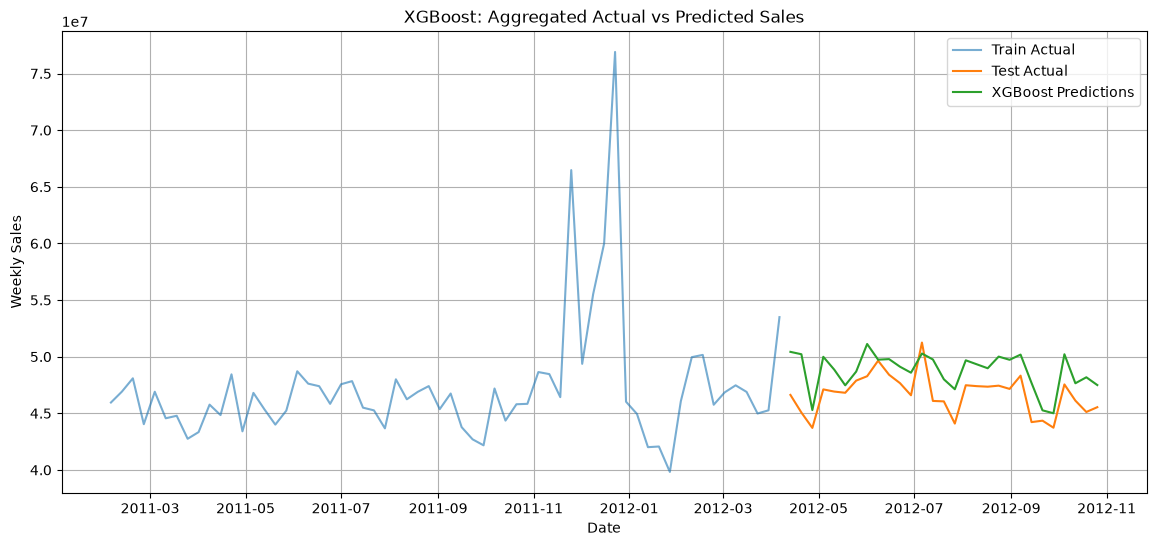

In [56]:
train_weekly = train_ml.groupby("Date")["Weekly_Sales"].sum()
test_weekly = test_ml.groupby("Date")["Weekly_Sales"].sum()

xgb_pred_df = test_ml[["Date"]].copy()
xgb_pred_df["Predicted"] = xgb_pred
xgb_pred_weekly = xgb_pred_df.groupby("Date")["Predicted"].sum()

plt.figure(figsize=(14,6))
plt.plot(train_weekly.index, train_weekly.values, label="Train Actual", alpha=0.6)
plt.plot(test_weekly.index, test_weekly.values, label="Test Actual")
plt.plot(xgb_pred_weekly.index, xgb_pred_weekly.values, label="XGBoost Predictions")

plt.title("XGBoost: Aggregated Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

In [57]:
import pandas as pd

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

xgb_importance.head(10)

,Feature,Importance
21,lag_52,0.581491
17,lag_1,0.197709
22,rolling_mean_4,0.119549
10,MarkDown3,0.013008
19,lag_4,0.012567
23,rolling_mean_12,0.010846
3,IsHoliday_x,0.010370
18,lag_2,0.004709
25,Type_B,0.003972
1,Dept,0.003964


# LightGBM

In [58]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------------- - 1.3/1.4 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 5.4 MB/s  0:00:00


In [59]:
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42
)

In [60]:
lgb_model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006934 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4494
[LightGBM] [Info] Number of data points in the train set: 176885, number of used features: 27
[LightGBM] [Info] Start training from score 16545.368366


,learning_rate,0.05
,n_estimators,200
,random_state,42
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [61]:
lgb_pred = lgb_model.predict(X_test)

In [62]:
lgb_mae = mean_absolute_error(y_test, lgb_pred)
lgb_rmse = np.sqrt(mean_squared_error(y_test, lgb_pred))

mask = y_test > 0
lgb_mape = np.mean(np.abs((y_test[mask] - lgb_pred[mask]) / y_test[mask])) * 100

print("=== LightGBM Results ===")
print(f"MAE:  {lgb_mae:,.2f}")
print(f"RMSE: {lgb_rmse:,.2f}")
print(f"MAPE: {lgb_mape:.2f}%")

=== LightGBM Results ===
MAE:  1,533.56
RMSE: 3,308.01
MAPE: 1010.61%


In [63]:
lgb_eval_df = test_ml[["Date", "Weekly_Sales"]].copy()
lgb_eval_df["Predicted"] = lgb_pred

lgb_agg = lgb_eval_df.groupby("Date").agg({
    "Weekly_Sales": "sum",
    "Predicted": "sum"
})

lgb_agg_mae = mean_absolute_error(lgb_agg["Weekly_Sales"], lgb_agg["Predicted"])
lgb_agg_rmse = np.sqrt(mean_squared_error(lgb_agg["Weekly_Sales"], lgb_agg["Predicted"]))

mask_agg = lgb_agg["Weekly_Sales"] > 0
lgb_agg_mape = np.mean(
    np.abs(
        (lgb_agg.loc[mask_agg, "Weekly_Sales"] - lgb_agg.loc[mask_agg, "Predicted"])
        / lgb_agg.loc[mask_agg, "Weekly_Sales"]
    )
) * 100

print("=== LightGBM (Aggregated) ===")
print(f"MAE:  {lgb_agg_mae:,.2f}")
print(f"RMSE: {lgb_agg_rmse:,.2f}")
print(f"MAPE: {lgb_agg_mape:.2f}%")

=== LightGBM (Aggregated) ===
MAE:  2,002,030.99
RMSE: 2,292,808.20
MAPE: 4.31%


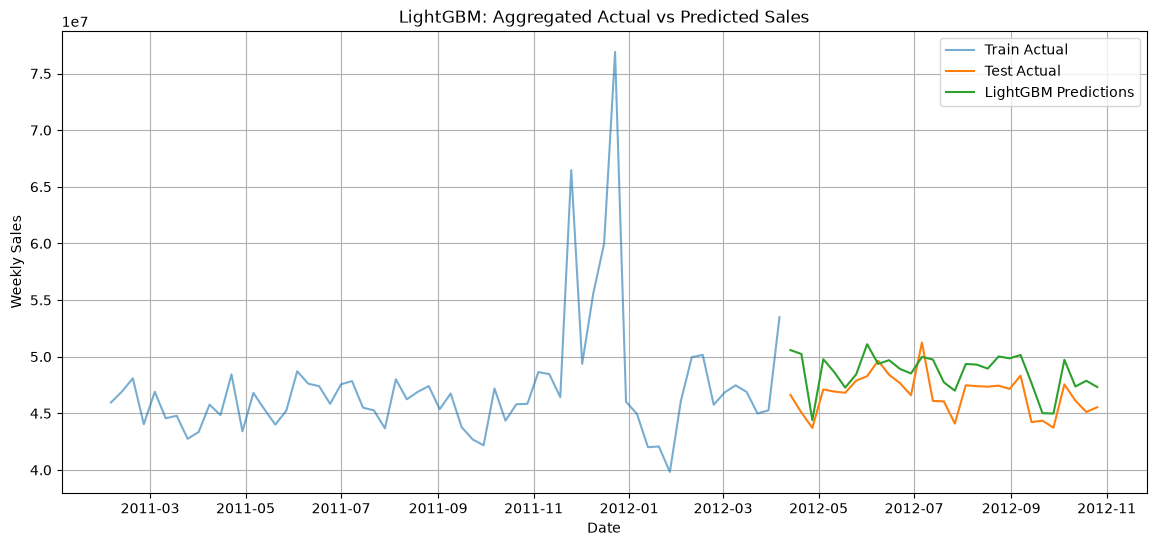

In [64]:
train_weekly = train_ml.groupby("Date")["Weekly_Sales"].sum()
test_weekly = test_ml.groupby("Date")["Weekly_Sales"].sum()

lgb_pred_df = test_ml[["Date"]].copy()
lgb_pred_df["Predicted"] = lgb_pred
lgb_pred_weekly = lgb_pred_df.groupby("Date")["Predicted"].sum()

plt.figure(figsize=(14, 6))
plt.plot(train_weekly.index, train_weekly.values, label="Train Actual", alpha=0.6)
plt.plot(test_weekly.index, test_weekly.values, label="Test Actual")
plt.plot(lgb_pred_weekly.index, lgb_pred_weekly.values, label="LightGBM Predictions")

plt.title("LightGBM: Aggregated Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

In [65]:
lgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

lgb_importance.head(10)

,Feature,Importance
21,lag_52,869
17,lag_1,721
1,Dept,544
15,Week,414
10,MarkDown3,394
24,rolling_std_4,391
20,lag_12,297
19,lag_4,273
18,lag_2,241
14,Month,219


XGBoost with better hyperparameter tuning

In [66]:
from xgboost import XGBRegressor

xgb_model_tuned = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1,
    random_state=42,
    n_jobs=-1
)

xgb_model_tuned.fit(X_train, y_train)
xgb_pred_tuned = xgb_model_tuned.predict(X_test)

In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_mae = mean_absolute_error(y_test, xgb_pred_tuned)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred_tuned))

mask = y_test > 0
xgb_mape = np.mean(np.abs((y_test[mask] - xgb_pred_tuned[mask]) / y_test[mask])) * 100

print("=== XGBoost Results ===")
print(f"MAE:  {xgb_mae:,.2f}")
print(f"RMSE: {xgb_rmse:,.2f}")
print(f"MAPE: {xgb_mape:.2f}%")

=== XGBoost Results ===
MAE:  1,472.48
RMSE: 3,124.41
MAPE: 832.22%


In [68]:
xgb_eval_df = test_ml[["Date", "Weekly_Sales"]].copy()
xgb_eval_df["Predicted"] = xgb_pred_tuned

xgb_agg = xgb_eval_df.groupby("Date").agg({
    "Weekly_Sales": "sum",
    "Predicted": "sum"
})

xgb_agg_mae = mean_absolute_error(xgb_agg["Weekly_Sales"], xgb_agg["Predicted"])
xgb_agg_rmse = np.sqrt(mean_squared_error(xgb_agg["Weekly_Sales"], xgb_agg["Predicted"]))

mask_agg = xgb_agg["Weekly_Sales"] > 0
xgb_agg_mape = np.mean(
    np.abs((xgb_agg.loc[mask_agg, "Weekly_Sales"] - xgb_agg.loc[mask_agg, "Predicted"]) / xgb_agg.loc[mask_agg, "Weekly_Sales"])
) * 100

print("=== XGBoost (Aggregated) ===")
print(f"MAE:  {xgb_agg_mae:,.2f}")
print(f"RMSE: {xgb_agg_rmse:,.2f}")
print(f"MAPE: {xgb_agg_mape:.2f}%")

=== XGBoost (Aggregated) ===
MAE:  2,002,105.38
RMSE: 2,344,940.90
MAPE: 4.31%
